# Milestone 2 — U-Net on Oxford-IIIT Pet: baseline run and proposed improvement

Three runs, same seed / split / architecture / optimiser, only the marked piece changes:

| Run | Augmentation | Loss | Role |
|---|---|---|---|
| `A_baseline` | no (resize only) | Cross-Entropy | the Milestone-1 baseline |
| `B_aug` | yes | Cross-Entropy | ablation: effect of augmentation alone |
| `C_aug_dice` | yes | Cross-Entropy + Dice | **proposed improvement** |

Classes (trimap − 1): `0` pet, `1` background, `2` ambiguous boundary.
Model selection uses the validation split; the official `test` split is evaluated once per run with the best-val checkpoint.

In [1]:
# [colab]
!pip install -q torch torchvision matplotlib numpy pillow

In [2]:
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from torchvision import tv_tensors

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # fixed input size -> faster convs
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.14.1+cu130 | device: cuda


In [3]:
# ---- experimental setup: every hyper-parameter lives here ----
CFG = dict(
    img_size=256,        # images bilinear, masks nearest
    batch_size=16,
    epochs=30,
    lr=1e-3,
    weight_decay=1e-4,
    base_ch=32,          # U-Net widths: 32-64-128-256-512
    val_frac=0.2,        # stratified per breed, from the 3680-image trainval split
    seed=42,
    num_workers=2,
)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet stats
CLASSES = ["Pet", "Background", "Boundary"]
BG = 1
EXPERIMENTS = [  # (name, augment, loss)
    ("A_baseline", False, "ce"),
    ("B_aug", True, "ce"),
    ("C_aug_dice", True, "ce_dice"),
]
RESULTS = {}

In [4]:
# [colab]
from torchvision.datasets import OxfordIIITPet

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/Pet-Image-Segmentation-CV'
    DATA_ROOT = '/content/data'   # local disk: Drive is slow/flaky under DataLoader workers (FileNotFoundError)
except ImportError:
    ROOT, DATA_ROOT = '.', './data'
OUT = f'{ROOT}/outputs'           # checkpoints, histories and figures persist on Drive
os.makedirs(OUT, exist_ok=True)

trainval_ds = OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='segmentation', download=True)
test_ds     = OxfordIIITPet(root=DATA_ROOT, split='test',     target_types='segmentation', download=True)

# torchvision only checks that the folders exist, so verify every file now instead of 10 minutes into training
for split, d in (('trainval', trainval_ds), ('test', test_ds)):
    missing = [p.name for p in d._images + d._segs if not p.exists()]
    assert not missing, f"{split}: {len(missing)} files missing, e.g. {missing[:3]}. Delete {DATA_ROOT}/oxford-iiit-pet and re-run."
print(len(trainval_ds), len(test_ds))

Mounted at /content/drive


100%|██████████| 792M/792M [00:38<00:00, 20.7MB/s]  
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.09MB/s]


3680 3669


In [5]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def stratified_split(labels, val_frac, seed):
    rng = np.random.RandomState(seed); tr, va = [], []
    for c in np.unique(labels):
        idx = rng.permutation(np.where(labels == c)[0]); k = int(round(len(idx) * val_frac))
        va += idx[:k].tolist(); tr += idx[k:].tolist()
    return sorted(tr), sorted(va)

train_idx, val_idx = stratified_split(np.array(trainval_ds._labels), CFG['val_frac'], CFG['seed'])
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_ds)}")

train 2944 | val 736 | test 3669


In [6]:
_CACHE = {}
def cached(base):
    # Decode + resize every image/mask ONCE (uint8, S x S) and keep it in RAM (~1 GB per split).
    # JPEG decoding on Colab's 2 CPU cores was the training bottleneck.
    if id(base) not in _CACHE:
        S = CFG['img_size']; rs = v2.Resize((S, S), antialias=True); out = []   # bilinear image, nearest mask
        for i in range(len(base)):
            img, m = base[i]
            m = tv_tensors.Mask(torch.from_numpy(np.array(m)) - 1)       # trimap 1/2/3 -> 0/1/2
            out.append(rs(v2.ToImage()(img), m))
        _CACHE[id(base)] = out
    return _CACHE[id(base)]

def make_tf(augment):
    S = CFG['img_size']; t = []
    if augment:   # applied jointly to image and mask; colour jitter touches the image only
        t += [v2.RandomResizedCrop(S, scale=(0.5, 1.0), antialias=True),
              v2.RandomHorizontalFlip(),
              v2.RandomRotation(15, fill={tv_tensors.Image: 0, tv_tensors.Mask: BG}),
              v2.ColorJitter(0.3, 0.3, 0.3, 0.05)]
    t += [v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)]
    return v2.Compose(t)

class PetSeg(Dataset):
    def __init__(self, base, indices, augment):
        self.data, self.idx, self.tf = cached(base), list(indices), make_tf(augment)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, m = self.tf(*self.data[self.idx[i]])
        return img, m.as_subclass(torch.Tensor).long()

def loader(base, idx, augment, shuffle):
    return DataLoader(PetSeg(base, idx, augment), batch_size=CFG['batch_size'], shuffle=shuffle,
                      drop_last=shuffle, num_workers=CFG['num_workers'], pin_memory=device.type == 'cuda')

In [7]:
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    # 4 down-steps (max-pool) / 4 up-steps (transposed conv) with skip connections, trained from scratch
    def __init__(self, in_ch=3, n_classes=3, c=32):
        super().__init__()
        ch = [c, c * 2, c * 4, c * 8, c * 16]
        self.enc = nn.ModuleList([block(in_ch, ch[0])] + [block(ch[i], ch[i + 1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([block(ch[i] * 2, ch[i]) for i in range(4)])
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([skips[i], self.up[i](x)], 1))
        return self.head(x)

print("U-Net params: %.2fM" % (sum(p.numel() for p in UNet(c=CFG['base_ch']).parameters()) / 1e6))

U-Net params: 7.76M


In [8]:
def dice_loss(logits, y, eps=1.0):   # soft Dice, averaged over the 3 classes
    p = logits.softmax(1); oh = F.one_hot(y, 3).permute(0, 3, 1, 2).float()
    inter = (p * oh).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

def objective(logits, y, kind):
    logits = logits.float()
    loss = F.cross_entropy(logits, y)
    return loss + dice_loss(logits, y) if kind == "ce_dice" else loss

def scores(cm):   # cm rows = ground truth, cols = prediction
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return tp / np.maximum(tp + fp + fn, 1), 2 * tp / np.maximum(2 * tp + fp + fn, 1)   # per-class IoU, Dice

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); cm = torch.zeros(9, dtype=torch.long, device=device); ce = 0.0; n = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            out = model(x)
        out = out.float()
        ce += F.cross_entropy(out, y, reduction='sum').item(); n += y.numel()
        cm += torch.bincount((y * 3 + out.argmax(1)).flatten(), minlength=9)
    cm = cm.view(3, 3).cpu().numpy(); iou, dice = scores(cm)
    return dict(cm=cm, ce=ce / n, miou=iou.mean(), mdice=dice.mean(), iou=iou, dice=dice)

In [9]:
def run_experiment(name, augment, loss_kind):
    set_seed(CFG['seed'])
    tr_dl = loader(trainval_ds, train_idx, augment, True)
    va_dl = loader(trainval_ds, val_idx, False, False)
    te_dl = loader(test_ds, range(len(test_ds)), False, False)
    model = UNet(c=CFG['base_ch']).to(device)
    ckpt, js = f'{OUT}/{name}.pt', f'{OUT}/{name}.json'
    meta = dict(cfg=CFG, augment=augment, loss=loss_kind)
    if os.path.exists(ckpt) and os.path.exists(js):
        saved = json.load(open(js))
        if {k: saved[k] for k in meta} == meta:   # finished earlier (e.g. before a disconnect): reload, don't retrain
            model.load_state_dict(torch.load(ckpt, map_location=device))
            print(f"[{name}] already trained (best epoch {saved['best_epoch']}) -> reloaded from {OUT}")
            return dict(name=name, model=model, hist=saved['hist'], best_epoch=saved['best_epoch'],
                        minutes=saved.get('minutes', float('nan')), val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['epochs'])
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    hist, best, t0 = [], (-1, 0), time.time()
    for ep in range(1, CFG['epochs'] + 1):
        model.train(); tl = 0.0
        for x, y in tr_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                out = model(x)
            loss = objective(out, y, loss_kind)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()
        sched.step()
        v = evaluate(model, va_dl)
        hist.append(dict(epoch=ep, train_loss=tl / len(tr_dl), val_ce=v['ce'], val_miou=v['miou'], val_mdice=v['mdice']))
        if v['miou'] > best[0]:
            best = (v['miou'], ep); torch.save(model.state_dict(), ckpt)
        print(f"[{name}] ep {ep:02d} train {hist[-1]['train_loss']:.4f} | val CE {v['ce']:.4f} mIoU {v['miou']:.4f} mDice {v['mdice']:.4f} | {(time.time() - t0) / 60:.1f} min")
    model.load_state_dict(torch.load(ckpt, map_location=device))
    res = dict(name=name, model=model, hist=hist, best_epoch=best[1], minutes=(time.time() - t0) / 60,
               val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    json.dump(dict(**meta, hist=hist, best_epoch=best[1], minutes=res['minutes'],
                   val_miou=res['val']['miou'], test_miou=res['test']['miou']), open(js, 'w'), indent=1)   # written last = "run finished"
    return res

Each run has its own cell. A finished run is reloaded from `outputs/` instead of retrained, so after a disconnect just re-run the cells in order.

In [10]:
RESULTS['A_baseline'] = run_experiment(*EXPERIMENTS[0])

[A_baseline] already trained (best epoch 26) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [11]:
RESULTS['B_aug'] = run_experiment(*EXPERIMENTS[1])

[B_aug] already trained (best epoch 29) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [12]:
RESULTS['C_aug_dice'] = run_experiment(*EXPERIMENTS[2])

[C_aug_dice] ep 01 train 1.3855 | val CE 0.7841 mIoU 0.4125 mDice 0.5523 | 1.0 min
[C_aug_dice] ep 02 train 1.2358 | val CE 0.6768 mIoU 0.4631 mDice 0.6002 | 1.8 min
[C_aug_dice] ep 03 train 1.1175 | val CE 0.5803 mIoU 0.5292 mDice 0.6720 | 2.6 min
[C_aug_dice] ep 04 train 1.0384 | val CE 0.5917 mIoU 0.5186 mDice 0.6642 | 3.5 min
[C_aug_dice] ep 05 train 0.9500 | val CE 0.5315 mIoU 0.5772 mDice 0.7143 | 4.3 min
[C_aug_dice] ep 06 train 0.8863 | val CE 0.4524 mIoU 0.6046 mDice 0.7344 | 5.1 min
[C_aug_dice] ep 07 train 0.8241 | val CE 0.4249 mIoU 0.6316 mDice 0.7563 | 6.0 min
[C_aug_dice] ep 08 train 0.7950 | val CE 0.4066 mIoU 0.6377 mDice 0.7617 | 6.8 min
[C_aug_dice] ep 09 train 0.7793 | val CE 0.4575 mIoU 0.6217 mDice 0.7498 | 7.7 min
[C_aug_dice] ep 10 train 0.7548 | val CE 0.4138 mIoU 0.6398 mDice 0.7652 | 8.5 min
[C_aug_dice] ep 11 train 0.7316 | val CE 0.3898 mIoU 0.6525 mDice 0.7748 | 9.4 min
[C_aug_dice] ep 12 train 0.6929 | val CE 0.3740 mIoU 0.6698 mDice 0.7880 | 10.2 min
[C_

## Results

In [13]:
hdr = f"{'run':<12}{'split':<6}{'mIoU':>7}{'mDice':>7}" + "".join(f"{'IoU '+c:>15}" for c in CLASSES) + f"{'best ep':>9}{'min':>6}"
print(hdr); print("-" * len(hdr))
for r in RESULTS.values():
    for split in ("val", "test"):
        s = r[split]
        print(f"{r['name']:<12}{split:<6}{s['miou']:>7.4f}{s['mdice']:>7.4f}" + "".join(f"{x:>15.4f}" for x in s['iou'])
              + (f"{r['best_epoch']:>9}{r['minutes']:>6.1f}" if split == "val" else ""))

run         split    mIoU  mDice        IoU Pet IoU Background   IoU Boundary  best ep   min
--------------------------------------------------------------------------------------------
A_baseline  val    0.7314 0.8319         0.8113         0.8963         0.4865       26   nan
A_baseline  test   0.7437 0.8416         0.8199         0.8999         0.5112
B_aug       val    0.7096 0.8162         0.7851         0.8821         0.4616       29  24.6
B_aug       test   0.7261 0.8293         0.7990         0.8884         0.4910
C_aug_dice  val    0.7193 0.8243         0.7897         0.8850         0.4832       28  25.6
C_aug_dice  test   0.7374 0.8384         0.8026         0.8927         0.5169


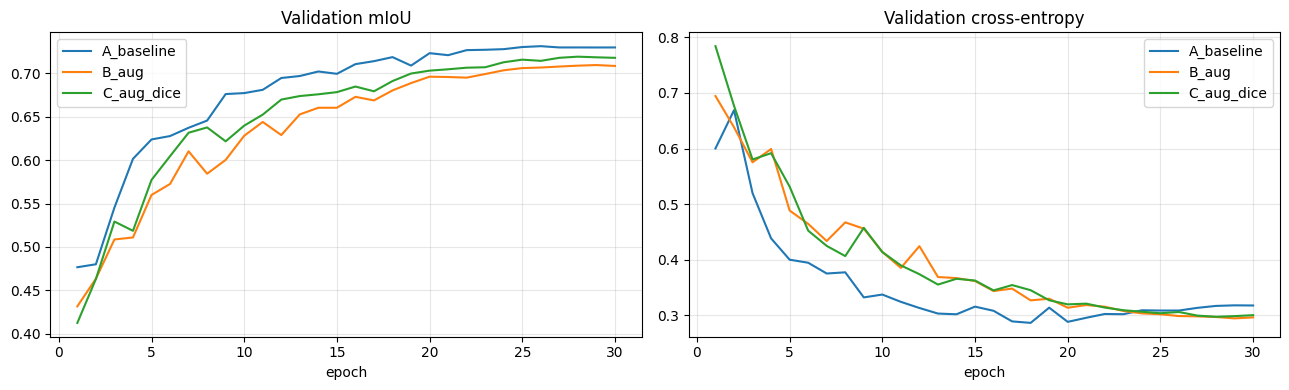

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in RESULTS.values():
    ep = [h['epoch'] for h in r['hist']]
    ax[0].plot(ep, [h['val_miou'] for h in r['hist']], label=r['name'])
    ax[1].plot(ep, [h['val_ce'] for h in r['hist']], label=r['name'])
ax[0].set(title="Validation mIoU", xlabel="epoch"); ax[1].set(title="Validation cross-entropy", xlabel="epoch")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT}/curves.png', dpi=150); plt.show()

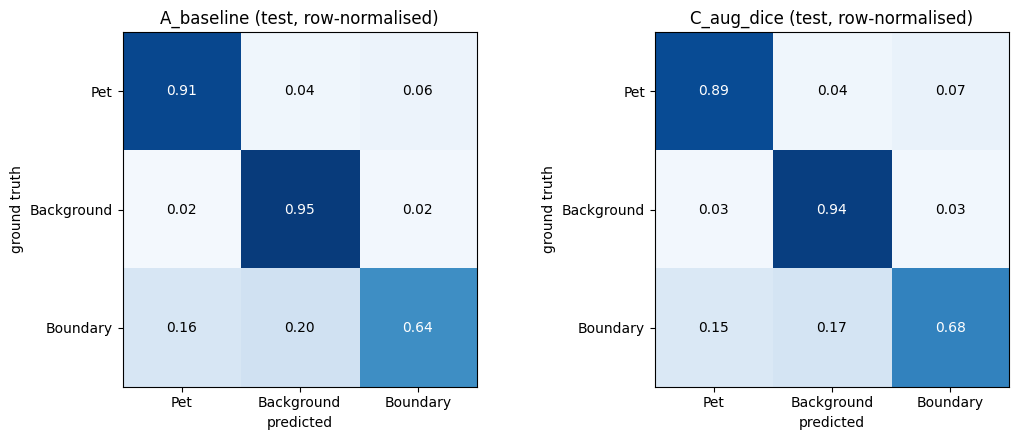

In [15]:
names = [EXPERIMENTS[0][0], EXPERIMENTS[-1][0]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, n in zip(ax, names):
    cm = RESULTS[n]['test']['cm']; cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    a.set(title=f"{n} (test, row-normalised)", xlabel="predicted", ylabel="ground truth",
          xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES)
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="w" if cmn[i, j] > .5 else "k")
plt.tight_layout(); plt.savefig(f'{OUT}/confusion_matrices.png', dpi=150); plt.show()

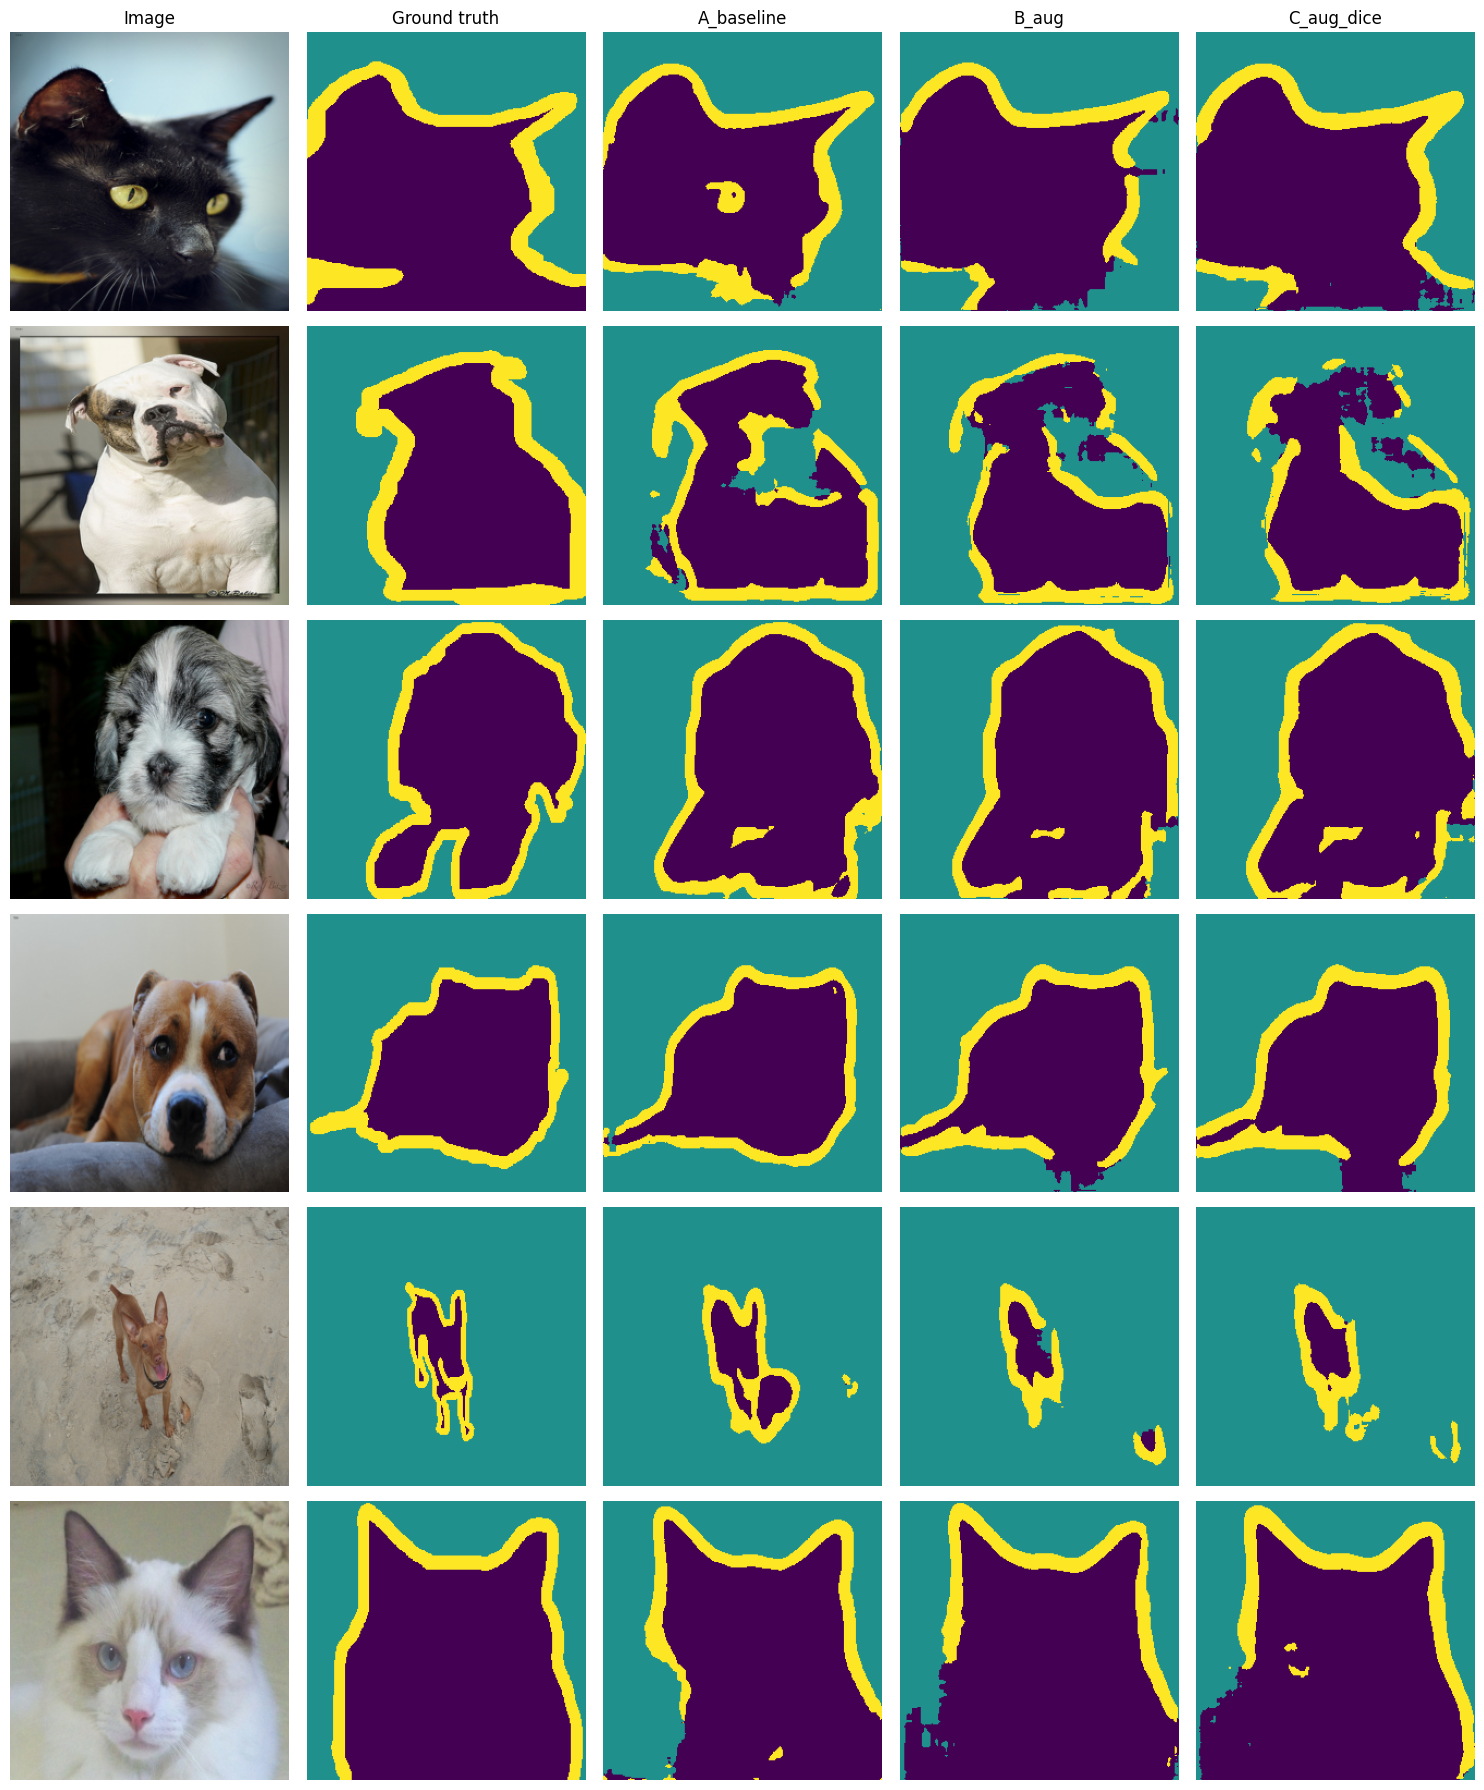

In [16]:
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
sel = np.random.RandomState(0).choice(len(test_ds), 6, replace=False)
ds = PetSeg(test_ds, sel, False); cols = ["Image", "Ground truth"] + [n for n, _, _ in EXPERIMENTS]
fig, ax = plt.subplots(len(sel), len(cols), figsize=(3 * len(cols), 3 * len(sel)))
for r, (x, y) in enumerate(ds):
    preds = []
    for n, _, _ in EXPERIMENTS:
        m = RESULTS[n]['model'].eval()
        with torch.no_grad(): preds.append(m(x[None].to(device)).argmax(1)[0].cpu())
    for c, im in enumerate([(x * std + mean).permute(1, 2, 0).clamp(0, 1), y] + preds):
        ax[r, c].imshow(im, **({} if c == 0 else dict(vmin=0, vmax=2, cmap="viridis"))); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(cols[c])
plt.tight_layout(); plt.savefig(f'{OUT}/predictions.png', dpi=120); plt.show()